In [51]:
#!git clone https://github.com/alexeygrigorev/clothing-dataset-small.git

In [6]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [7]:
#%pip install tensorflow

In [8]:
import tensorflow as tf
from tensorflow import keras

I0000 00:00:1795523857.312468   10126 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795523878.160840   10126 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795523894.300666   10126 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [9]:
from tensorflow.keras.preprocessing.image import load_img

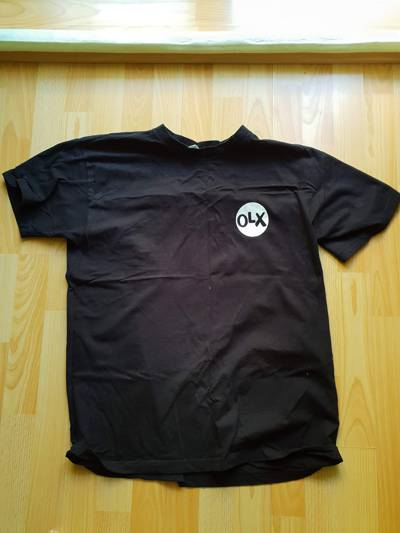

In [10]:
path = './clothing-dataset-small/train/t-shirt'
name = '5f0a3fa0-6a3d-4b68-b213-72766a643de7.jpg'
fullname = f'{path}/{name}'
load_img(fullname)

In [11]:
img = load_img(fullname, target_size=(299,299))
print(img)

<PIL.Image.Image image mode=RGB size=299x299 at 0x714E425DFE00>


In [12]:
x = np.array(img)
x.shape

(299, 299, 3)

## Pre-trained convolutional neural networks

In [13]:
from tensorflow.keras.applications.xception import Xception
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras.applications.xception import decode_predictions

In [14]:
model = Xception(weights='imagenet', input_shape=(299, 299, 3))

E0000 00:00:1795523915.105302   10126 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [15]:
X = np.array([x])

In [16]:
X.shape

(1, 299, 299, 3)

In [17]:
X = preprocess_input(X)

In [18]:
X[0]

array([[[ 0.4039216 ,  0.3411765 , -0.2235294 ],
        [ 0.4039216 ,  0.3411765 , -0.2235294 ],
        [ 0.41960788,  0.35686278, -0.20784312],
        ...,
        [ 0.96862745,  0.9843137 ,  0.94509804],
        [ 0.96862745,  0.9843137 ,  0.94509804],
        [ 0.96862745,  0.99215686,  0.9372549 ]],

       [[ 0.47450984,  0.4039216 , -0.12156862],
        [ 0.4666667 ,  0.39607847, -0.12941176],
        [ 0.45882356,  0.38823533, -0.15294117],
        ...,
        [ 0.96862745,  0.9764706 ,  0.9372549 ],
        [ 0.96862745,  0.9764706 ,  0.9372549 ],
        [ 0.96862745,  0.9764706 ,  0.92941177]],

       [[ 0.56078434,  0.48235297, -0.00392157],
        [ 0.5686275 ,  0.4901961 ,  0.00392163],
        [ 0.5686275 ,  0.49803925, -0.01176471],
        ...,
        [ 0.9607843 ,  0.96862745,  0.92156863],
        [ 0.9607843 ,  0.96862745,  0.92156863],
        [ 0.9607843 ,  0.96862745,  0.92156863]],

       ...,

       [[ 0.2941177 ,  0.18431377, -0.40392154],
        [ 0

In [19]:
pred = model.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


In [20]:
pred.shape

(1, 1000)

In [21]:
decode_predictions(pred)

[[('n03595614', 'jersey', np.float32(0.6819624)),
  ('n02916936', 'bulletproof_vest', np.float32(0.03814022)),
  ('n04370456', 'sweatshirt', np.float32(0.034324754)),
  ('n03710637', 'maillot', np.float32(0.011354213)),
  ('n04525038', 'velvet', np.float32(0.0018453635))]]

## Convolutional neural networks

## Transfer learning

In [22]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [23]:
train_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_ds = train_gen.flow_from_directory(
    './clothing-dataset-small/train',
    target_size=(150, 150),
    batch_size=32
)

Found 3068 images belonging to 10 classes.


In [24]:
#!ls -l clothing-dataset-small/train

In [25]:
train_ds.class_indices

{'dress': 0,
 'hat': 1,
 'longsleeve': 2,
 'outwear': 3,
 'pants': 4,
 'shirt': 5,
 'shoes': 6,
 'shorts': 7,
 'skirt': 8,
 't-shirt': 9}

In [26]:
X, y = next(train_ds)

In [27]:
X.shape
y[:5]

array([[0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

In [28]:
val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory(
    './clothing-dataset-small/validation',
    target_size=(150, 150),
    batch_size=32, 
    shuffle=False
)

Found 341 images belonging to 10 classes.


In [29]:
base_model = Xception(
    weights='imagenet', 
    include_top = False, 
    input_shape = (150, 150, 3)
)
base_model.trainable = False

inputs = keras.Input(shape = (150, 150, 3)) 

base = base_model(inputs, training=False)

#pooling = keras.layers.GlobalAveragePooling2D()
#vectors = pooling(base)
vectors = keras.layers.GlobalAveragePooling2D()(base)

outputs = keras.layers.Dense(10)(vectors)

model = keras.Model(inputs, outputs)

In [30]:
learning_rate = 0.01
optimizer = keras.optimizers.Adam(learning_rate=learning_rate)

loss = keras.losses.CategoricalCrossentropy(from_logits=True)

model.compile(optimizer = optimizer, loss = loss, metrics=['accuracy'])

In [27]:
history = model.fit(train_ds, epochs=10, validation_data=val_ds)

Epoch 1/10


I0000 00:00:1795451854.210639    2754 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


96/96 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - accuracy: 0.6721 - loss: 1.2321 - val_accuracy: 0.7771 - val_loss: 0.8916
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.8308 - loss: 0.5366 - val_accuracy: 0.7742 - val_loss: 0.9139
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 0.8742 - loss: 0.3863 - val_accuracy: 0.8094 - val_loss: 0.7713
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.9110 - loss: 0.2467 - val_accuracy: 0.8035 - val_loss: 0.8682
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.9469 - loss: 0.1554 - val_accuracy: 0.8006 - val_loss: 0.8780
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.9700 - loss: 0.0872 - val_accuracy: 0.8211 - val_loss: 0.7559
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.9831 - loss: 0.0614 - val_accuracy: 0.8123 - val_loss: 0.9275
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.9896 - loss: 0.0485 - val_accuracy: 0.8240 - val_loss: 0.

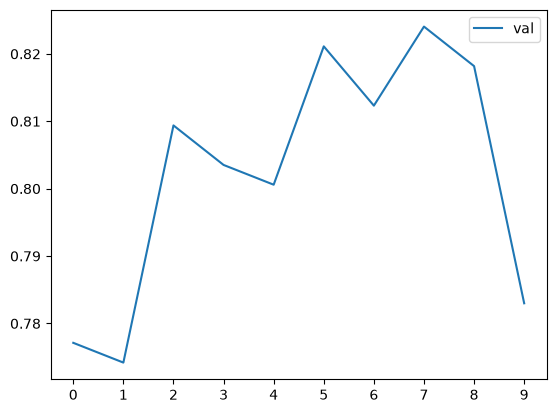

In [28]:
#plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.xticks(np.arange(10))
plt.legend()

## Adjusting the learning rate

In [34]:
def make_model(learning_rate = 0.01):
    base_model = Xception(
        weights='imagenet', 
        include_top = False, 
        input_shape = (150, 150, 3)
    )
    base_model.trainable = False
    
    ###########################################
    
    inputs = keras.Input(shape = (150, 150, 3))  
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)
    outputs = keras.layers.Dense(10)(vectors)
    model = keras.Model(inputs, outputs)

    ###########################################
    
    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)
    
    model.compile(
        optimizer = optimizer, 
        loss = loss, 
        metrics=['accuracy'])

    return model

In [35]:
scores = {}

for lr in [0.0001, 0.001, 0.01, 0.1]:
    print(lr)

    model = make_model(learning_rate=lr)
    history = model.fit(train_ds, epochs=10, validation_data=val_ds)
    scores[lr] = history.history
    
    print()
    print()

0.0001
Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 149s 2s/step - accuracy: 0.3155 - loss: 2.0138 - val_accuracy: 0.4457 - val_loss: 1.6748
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.5456 - loss: 1.4298 - val_accuracy: 0.6158 - val_loss: 1.3072
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 201s 1s/step - accuracy: 0.6379 - loss: 1.1659 - val_accuracy: 0.6716 - val_loss: 1.1025
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.6855 - loss: 1.0188 - val_accuracy: 0.7009 - val_loss: 0.9834
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 144s 2s/step - accuracy: 0.7080 - loss: 0.9193 - val_accuracy: 0.7155 - val_loss: 0.9013
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 146s 2s/step - accuracy: 0.7272 - loss: 0.8485 - val_accuracy: 0.7507 - val_loss: 0.8441
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.7405 - loss: 0.7942 - val_accuracy: 0.7625 - val_loss: 0.8040
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 145s 2s/step - accuracy: 0.7585 - loss: 0.7505 - val_accuracy: 0.7

In [37]:
del scores[0.1]
del scores[0.0001]

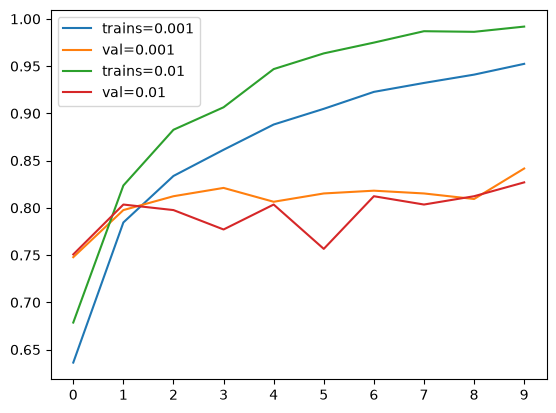

In [38]:
for lr, hist in scores.items():
    plt.plot(hist['accuracy'], label=('trains=%s' % lr))
    plt.plot(hist['val_accuracy'], label=('val=%s' % lr))

plt.xticks(np.arange(10))
plt.legend()

In [39]:
learning_rate = 0.001

## Checkpointing 

In [41]:
model.save_weights('model_v1.weights.h5')

In [43]:
keras.callbacks.ModelCheckpoint('xception_v1_{epoch:02d}_{val_accuracy:.3f}.weights.h5')

In [45]:
chechpoint = keras.callbacks.ModelCheckpoint(
    'xception_v1_{epoch:02d}_{val_accuracy:.3f}.weights.h5',
    save_best_only=True,
    monitor='val_accuracy',
    mode='max'
)

In [47]:
learning_rate = 0.001

model = make_model(learning_rate=learning_rate)

history = model.fit(
    train_ds, 
    epochs=10,
    validation_data=val_ds,
    callbacks=[chechpoint]
)


Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6248 - loss: 1.0998

96/96 ━━━━━━━━━━━━━━━━━━━━ 132s 1s/step - accuracy: 0.6248 - loss: 1.0998 - val_accuracy: 0.7566 - val_loss: 0.7238
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7865 - loss: 0.6307

96/96 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.7865 - loss: 0.6307 - val_accuracy: 0.7801 - val_loss: 0.6629
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8286 - loss: 0.5092

96/96 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.8286 - loss: 0.5092 - val_accuracy: 0.7947 - val_loss: 0.5876
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8654 - loss: 0.4256

96/96 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - accuracy: 0.8654 - loss: 0.4256 - val_accuracy: 0.8065 - val_loss: 0.5682
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.8859 - loss: 0.3718 - val_accuracy: 0.8035 - val_loss: 0.5663
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9071 - loss: 0.3244

96/96 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 0.9071 - loss: 0.3244 - val_accuracy: 0.8211 - val_loss: 0.5383
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.9250 - loss: 0.2894 - val_accuracy: 0.8182 - val_loss: 0.5326
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 0.9322 - loss: 0.2556 - val_accuracy: 0.8211 - val_loss: 0.5338
Epoch 9/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9443 - loss: 0.2316

96/96 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 0.9443 - loss: 0.2316 - val_accuracy: 0.8270 - val_loss: 0.5370
Epoch 10/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 0.9524 - loss: 0.2084 - val_accuracy: 0.8240 - val_loss: 0.5419


## Adding More Layers 

In [52]:
def make_model(learning_rate = 0.01, size_inner = 100):
    base_model = Xception(
        weights='imagenet', 
        include_top = False, 
        input_shape = (150, 150, 3)
    )
    base_model.trainable = False
    
    ###########################################
    
    inputs = keras.Input(shape = (150, 150, 3))  
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)

    inner = keras.layers.Dense(size_inner, activation='relu')(vectors)
    
    outputs = keras.layers.Dense(10, activation='softmax')(inner)
    
    model = keras.Model(inputs, outputs)

    ###########################################
    
    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)
    
    model.compile(
        optimizer = optimizer, 
        loss = loss, 
        metrics=['accuracy'])

    return model

In [53]:
learning_rate = 0.001

scores = {}

for size in [10, 100, 1000]:
    print(size)

    model = make_model(learning_rate=learning_rate, size_inner = size)
    history = model.fit(train_ds, epochs=10, validation_data=val_ds)
    scores[size] = history.history
    
    print()
    print()

10
Epoch 1/10


/usr/local/python/3.14.2/lib/python3.14/site-packages/keras/src/backend/tensorflow/ops/nn.py:1483: UserWarning: "`categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


96/96 ━━━━━━━━━━━━━━━━━━━━ 134s 1s/step - accuracy: 0.5359 - loss: 1.3528 - val_accuracy: 0.6598 - val_loss: 0.9832
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.7327 - loss: 0.8043 - val_accuracy: 0.7449 - val_loss: 0.7691
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.7911 - loss: 0.6285 - val_accuracy: 0.7830 - val_loss: 0.6718
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.8227 - loss: 0.5149 - val_accuracy: 0.7977 - val_loss: 0.6375
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.8618 - loss: 0.4382 - val_accuracy: 0.8035 - val_loss: 0.6236
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.8856 - loss: 0.3814 - val_accuracy: 0.8152 - val_loss: 0.5737
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.9078 - loss: 0.3271 - val_accuracy: 0.7947 - val_loss: 0.5818
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.9208 - loss: 0.2907 - val_accuracy: 0.8328 - val_loss: 0.

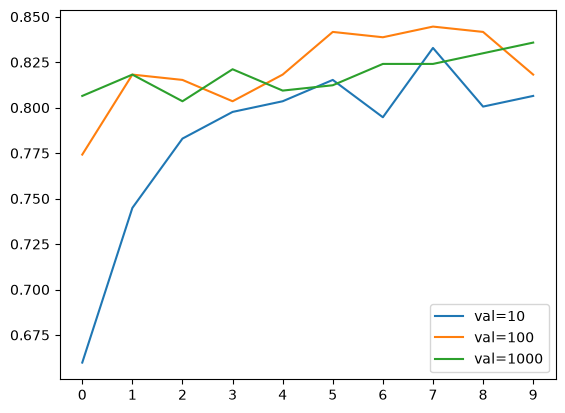

In [54]:
for size, hist in scores.items():
    plt.plot(hist['val_accuracy'], label=('val=%s' % size))

plt.xticks(np.arange(10))
plt.legend()

## Regularization and Dropout

In [33]:
def make_model(learning_rate = 0.01, size_inner = 100, droprate = 0.5):
    base_model = Xception(
        weights='imagenet', 
        include_top = False, 
        input_shape = (150, 150, 3)
    )
    base_model.trainable = False
    
    ###########################################
    
    inputs = keras.Input(shape = (150, 150, 3))  
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)

    inner = keras.layers.Dense(size_inner, activation='relu')(vectors)
    drop = keras.layers.Dropout(droprate)(inner)
    
    outputs = keras.layers.Dense(10, activation='softmax')(drop)
    
    model = keras.Model(inputs, outputs)

    ###########################################
    
    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)
    
    model.compile(
        optimizer = optimizer, 
        loss = loss, 
        metrics=['accuracy'])

    return model

## Upgrade velocity

In [36]:
base_model = Xception(weights='imagenet', include_top=False, input_shape=(150, 150, 3))
base_model.trainable = False

inputs = keras.Input(shape=(150, 150, 3))
base = base_model(inputs, training=False)
vectors = keras.layers.GlobalAveragePooling2D()(base)
extractor = keras.Model(inputs, vectors)

def extract_features(ds):
    ds.reset()
    features_list = []
    labels_list = []
    for _ in range(len(ds)):
        x_batch, y_batch = next(ds)
        feat_batch = extractor.predict(x_batch, verbose=0)
        features_list.append(feat_batch)
        labels_list.append(y_batch)
    return np.vstack(features_list), np.vstack(labels_list)

X_train_feat, y_train = extract_features(train_ds)
X_val_feat, y_val = extract_features(val_ds)

print("X_train_feat:", X_train_feat.shape)

X_train_feat: (3068, 2048)


In [37]:
def make_fast_model(learning_rate=0.001, size_inner=100, droprate=0.5):
    inputs = keras.Input(shape=(2048,))
    inner = keras.layers.Dense(size_inner, activation='relu')(inputs)
    drop = keras.layers.Dropout(droprate)(inner)
    outputs = keras.layers.Dense(10)(drop)
    
    model = keras.Model(inputs, outputs)
    
    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)
    model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])
    return model

In [40]:
learning_rate = 0.001
size = 100
scores = {}

for droprate in [0.0, 0.2, 0.5, 0.8]:
    print(droprate)
    model = make_fast_model(
        learning_rate=learning_rate,
        size_inner=size,
        droprate=droprate
    )
    history = model.fit(
        X_train_feat, y_train,
        epochs=30,
        batch_size=32,
        validation_data=(X_val_feat, y_val),
        verbose=0
    )
    scores[droprate] = history.history
    print(f"the best val_accuracy: {max(history.history['val_accuracy']):.4f}\n")

0.0
the best val_accuracy: 0.8270

0.2
the best val_accuracy: 0.8299

0.5
the best val_accuracy: 0.8446

0.8
the best val_accuracy: 0.8299



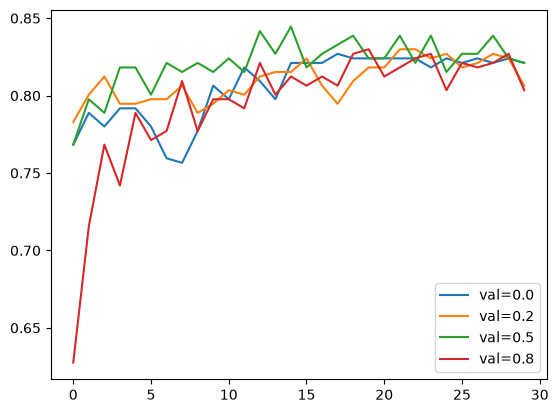

In [42]:
for droprate, hist in scores.items():
    plt.plot(hist['val_accuracy'], label=('val=%s' % droprate))

plt.legend()

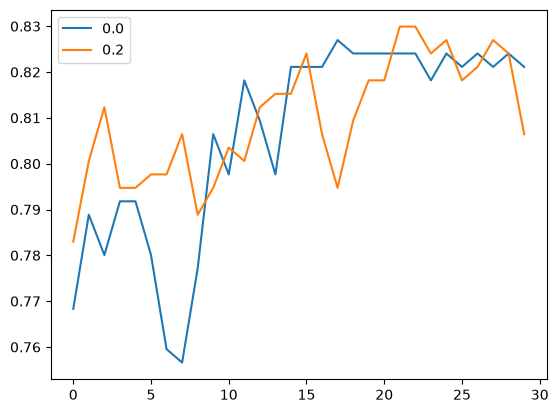

In [47]:
hist = scores[0.0]
plt.plot(hist['val_accuracy'], label=0.0)

hist = scores[0.2]
plt.plot(hist['val_accuracy'], label=0.2)

plt.legend()

## Data augmentation